In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**loading spectrograms and log-mel 1D, augmentation**

In [ ]:
import os
import numpy as np
from PIL import Image
import random

# Constants
spectrogram_dir = "/content/drive/My Drive/Spectrograms/Spectrograms128_FSDD/"
img_height = 128
img_width = 128

def apply_spec_augment(log_mel_spec, time_mask_num=2, freq_mask_num=2, max_time_mask=15, max_freq_mask=15):
    """Apply SpecAugment to a single spectrogram."""
    augmented_spec = log_mel_spec.copy()

    # Time masking
    for _ in range(time_mask_num):
        t = random.randint(0, max_time_mask)  # Random time mask length
        t0 = random.randint(0, log_mel_spec.shape[0] - t)
        augmented_spec[t0:t0 + t, :] = 0  # Mask by setting values to 0

    # Frequency masking
    for _ in range(freq_mask_num):
        f = random.randint(0, max_freq_mask)  # Random frequency mask length
        f0 = random.randint(0, log_mel_spec.shape[1] - f)
        augmented_spec[:, f0:f0 + f] = 0  # Mask by setting values to 0

    return augmented_spec


def load_and_preprocess_spectrograms(spectrogram_dir, apply_augmentation=True, augmentation_factor=1):
    """
    Load spectrograms, apply SpecAugment, and optionally generate more samples.

    Parameters:
    - spectrogram_dir: Directory containing spectrogram images.
    - apply_augmentation: Whether to apply SpecAugment.
    - augmentation_factor: Number of augmented versions to create per original sample.

    Returns:
    - spectrograms: Numpy array of preprocessed spectrograms.
    - labels: Numpy array of corresponding labels.
    """
    spectrograms = []
    labels = []

    for file_name in os.listdir(spectrogram_dir):
        if file_name.endswith('.png'):
            # Extract label from file name (e.g., "7_jackson_32.png")
            label = int(file_name.split('_')[0])

            # Load the image
            img_path = os.path.join(spectrogram_dir, file_name)
            img = Image.open(img_path).convert("L")  # Converting to grayscale
            # Resize image
            img = img.resize((img_width, img_height))

            # Convert to numpy array and normalize
            img_array = np.array(img) / 255.0

            # Log-mel transformation
            log_mel_spec = np.log1p(img_array)  # log(1 + spectrogram)

            # Add original sample
            log_mel_spec_1d = np.mean(log_mel_spec, axis=0)  # Average across height
            spectrograms.append(log_mel_spec_1d)
            labels.append(label)

            # Create augmented samples
            if apply_augmentation:
                for _ in range(augmentation_factor):
                    augmented_spec = apply_spec_augment(log_mel_spec)
                    augmented_spec_1d = np.mean(augmented_spec, axis=0)
                    spectrograms.append(augmented_spec_1d)
                    labels.append(label)

    return np.array(spectrograms), np.array(labels)

# Load spectrograms with 2 augmented versions per original sample
X, y = load_and_preprocess_spectrograms(spectrogram_dir, apply_augmentation=True, augmentation_factor=5)
# Expand dimensions to add the channel for Conv1D
X = np.expand_dims(X, axis=-1)
print(f"Spectrograms shape: {X.shape}, Labels shape: {y.shape}")


Spectrograms shape: (18000, 128, 1), Labels shape: (18000,)


**dividing to train, test & validation**

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Number of samples per class in the test set
test_size_per_class = 600 // 10  # 10 labels, equal distribution

# Initialize lists to store the splits
X_test, y_test = [], []
X_train_val, y_train_val = [], []

# Get unique classes
classes = np.unique(y)

# Create the test set with equal samples per class
for label in classes:
    # Get all samples for the current label
    label_indices = np.where(y == label)[0]
    X_label = X[label_indices]
    y_label = y[label_indices]

    # Extract test samples for this label
    X_label_test, X_label_train_val, y_label_test, y_label_train_val = train_test_split(
        X_label, y_label, test_size=(len(X_label) - test_size_per_class), random_state=42
    )

    # Append to test and remaining data lists
    X_test.append(X_label_test)
    y_test.append(y_label_test)
    X_train_val.append(X_label_train_val)
    y_train_val.append(y_label_train_val)

# Concatenate the splits
X_test = np.concatenate(X_test, axis=0)
y_test = np.concatenate(y_test, axis=0)
X_train_val = np.concatenate(X_train_val, axis=0)
y_train_val = np.concatenate(y_train_val, axis=0)

# Split the remaining data into training and validation sets (90% train, 10% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1, stratify=y_train_val, random_state=42
)

# Print the final shapes
print(f"Training set: {X_train.shape}")
print(f"Validation set: {X_val.shape}")
print(f"Test set: {X_test.shape}")


Training set: (15660, 128, 1)
Validation set: (1740, 128, 1)
Test set: (600, 128, 1)


In [ ]:
!pip install tensorflow.keras
!pip install keras


**defining Conv1D, pos. encoding blocks**

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Conv1D, Input, Lambda, Add, LayerNormalization, Activation

def create_conv1d_input(input_shape, num_filters, kernel_size):
    """
    Creates the Conv1D input layer and its output.
    """
    input_layer = Input(shape=input_shape)
    conv_output = Conv1D(filters=num_filters, kernel_size=kernel_size, padding='same')(input_layer)
    conv_output = Activation('gelu')(conv_output)  # Using GELU activation
    return input_layer, conv_output

def positional_encoding(seq_len, d_model):
    """
    Computes the positional encoding for the given sequence length and model dimension.
    """
    positions = tf.range(seq_len, dtype=tf.float32)[:, tf.newaxis]
    dimensions = tf.range(d_model, dtype=tf.float32)[tf.newaxis, :]
    angle_rads = positions / tf.pow(10000.0, (2 * (dimensions // 2)) / d_model)

    # Apply sin to even indices and cos to odd indices
    sines = tf.math.sin(angle_rads[:, 0::2])
    cosines = tf.math.cos(angle_rads[:, 1::2])
    pos_encoding = tf.concat([sines, cosines], axis=-1)
    return pos_encoding

def add_positional_encoding(inputs, seq_len, d_model):
    """
    Adds positional encoding to the input tensor.
    """
    pos_encoding = positional_encoding(seq_len, d_model)
    # Positional encoding has shape (1, seq_len, d_model); broadcast it to match input shape
    pos_encoding = tf.expand_dims(pos_encoding, axis=0)  # Add batch dimension
    pos_encoding = tf.tile(pos_encoding, [tf.shape(inputs)[0], 1, 1])  # Match batch size
    return Add()([inputs, pos_encoding])

**Building the iniatial model**

In [ ]:
input_shape = (128, 1)  # Spectrogram shape (sequence_length, channels)
num_filters = 64        # Number of Conv1D filters
kernel_size = 7         # Kernel size for Conv1D
d_model = num_filters    # Positional encoding dimension matches Conv1D filters
seq_len = 128
# Create layers
input_layer, conv_output = create_conv1d_input(input_shape, num_filters, kernel_size)
# encoded_output = add_positional_encoding(conv_output, seq_len, d_model)
encoded_output = Lambda(lambda x: add_positional_encoding(x, seq_len=128, d_model=d_model))(conv_output)

# Build the model
model = tf.keras.Model(inputs=input_layer, outputs=encoded_output)
#model.summary()


**defining transformer encoder and building the final model**

In [ ]:
from keras.layers import Input, Embedding, MultiHeadAttention, Dense, LayerNormalization, Dropout, Add, Lambda
from keras.models import Model
import tensorflow as tf

# Transformer Encoder
def transformer_encoder(input_tensor, num_heads, ff_dim, num_blocks, dropout_rate):
    x = input_tensor
    for _ in range(num_blocks):
        # Multi-Head Self-Attention
        attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=input_tensor.shape[-1])(x, x)
        attention_output = Dropout(dropout_rate)(attention_output)
        x = Add()([x, attention_output])
        x = LayerNormalization(epsilon=1e-6)(x)

        # Feed-Forward Network
        ff_output = Dense(ff_dim, activation='gelu')(x)
        ff_output = Dense(input_tensor.shape[-1])(ff_output)
        ff_output = Dropout(dropout_rate)(ff_output)
        x = Add()([x, ff_output])
        x = LayerNormalization(epsilon=1e-6)(x)
    return x

# Parameters
seq_len = 128
embedding_dim = 64  # Matches Conv1D filters and positional encoding dimension
num_heads = 8
ff_dim = 512
num_blocks = 2
dropout_rate = 0.4
# vocab_size = 5000  # Example vocab size for tokenized inputs
output_classes = 10  # Number of classes for classification

# Encoder
encoder_output = transformer_encoder(encoded_output, num_heads, ff_dim, num_blocks, dropout_rate)

# Global Average Pooling
pooled_output = tf.keras.layers.GlobalAveragePooling1D()(encoder_output)

# Classification Output
final_output = Dense(output_classes, activation="softmax", name="classification_output")(pooled_output)

# Complete Model
model = Model(inputs=input_layer, outputs=final_output)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])



**plotting the model**

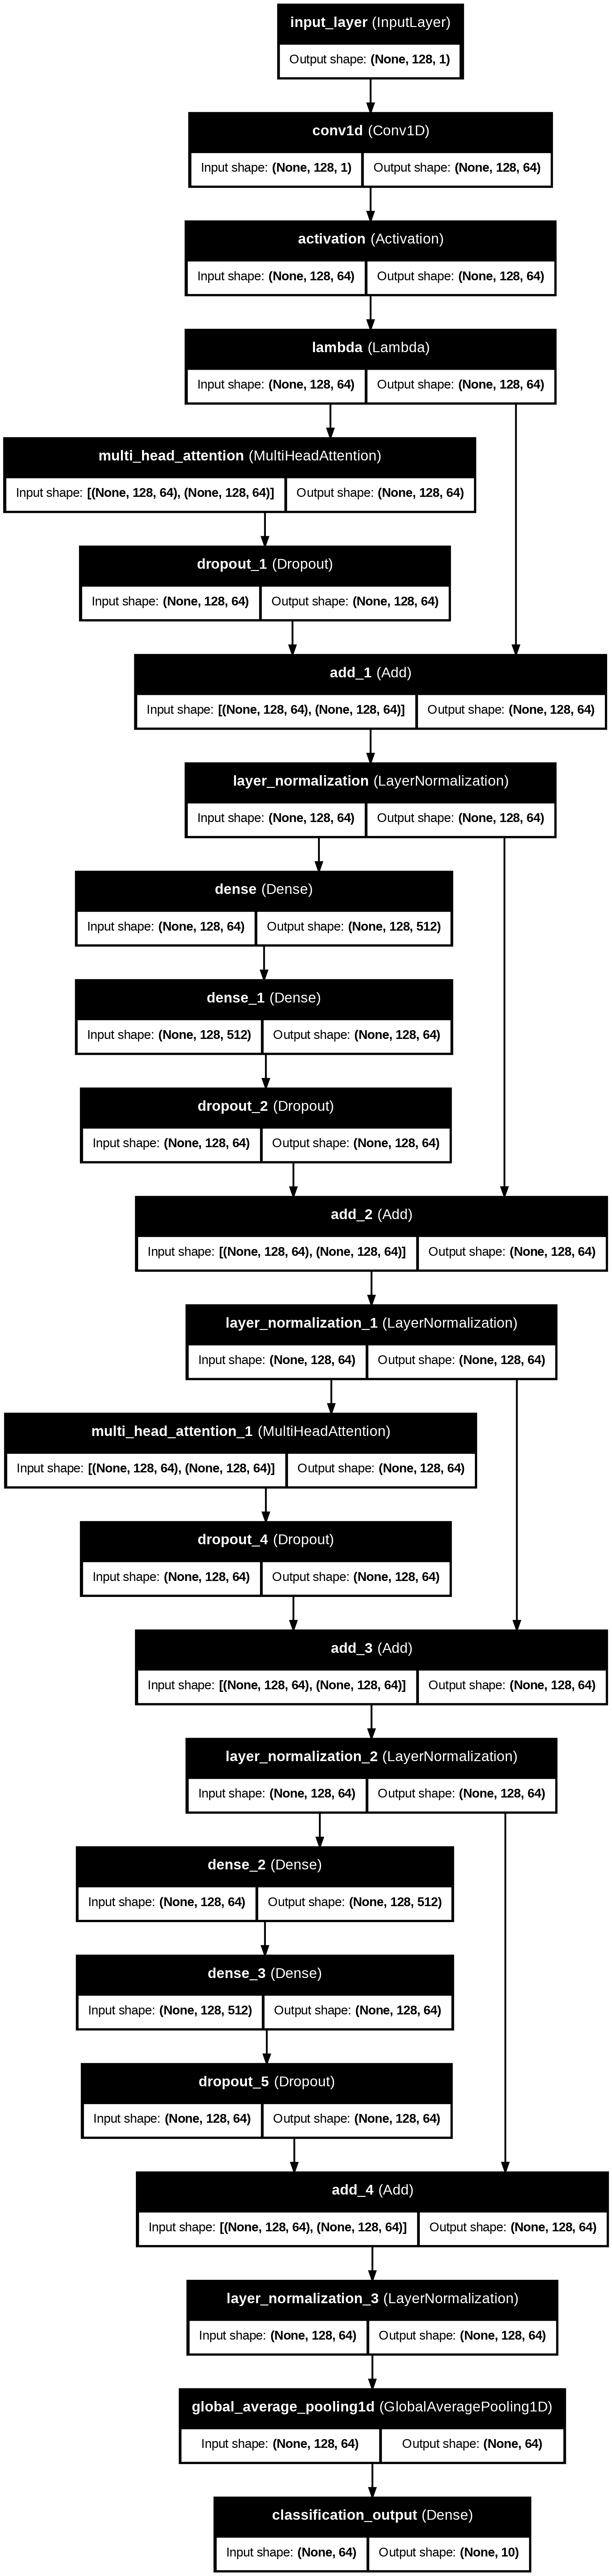

In [ ]:
from tensorflow.keras.utils import plot_model

# Visualize the model architecture
# model.summary()  # Textual representation

# Generate a graphical representation
plot_model(model, to_file="model_architecture.png", show_shapes=True, show_layer_names=True)

# If running in Colab, display the image
from IPython.display import Image
Image(filename="model_architecture.png")

**defining needed callbacks**

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Save the best model
model_checkpoint = ModelCheckpoint(
    "best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    save_weights_only=False,  # Save the entire model, not just weights
    mode="max",
    verbose=1
)

# Other Callbacks
early_stopping = EarlyStopping(monitor="val_loss", patience=10, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=4, verbose=1)


**training the model**

In [ ]:
batch_size = 32
epochs = 70

# Training the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[early_stopping, reduce_lr, model_checkpoint],
)


Epoch 1/70
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 877ms/step - accuracy: 0.1012 - loss: 2.3874
Epoch 1: val_accuracy improved from -inf to 0.10057, saving model to best_model.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 457s 912ms/step - accuracy: 0.1012 - loss: 2.3873 - val_accuracy: 0.1006 - val_loss: 2.3117 - learning_rate: 0.0010
Epoch 2/70
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 948ms/step - accuracy: 0.1188 - loss: 2.2972
Epoch 2: val_accuracy improved from 0.10057 to 0.23448, saving model to best_model.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 536s 982ms/step - accuracy: 0.1189 - loss: 2.2971 - val_accuracy: 0.2345 - val_loss: 2.1123 - learning_rate: 0.0010
Epoch 3/70
490/490 ━━━━━━━━━━━━━━━━━━━━ 0s 847ms/step - accuracy: 0.2740 - loss: 2.0366
Epoch 3: val_accuracy improved from 0.23448 to 0.34253, saving model to best_model.keras
490/490 ━━━━━━━━━━━━━━━━━━━━ 431s 880ms/step - accuracy: 0.2740 - loss: 2.0364 - val_accuracy: 0.3425 - val_loss: 1.8928 - learning_rate: 0.0010
Epoch 4/70
490/490 ━━━━━━━━━━━━━━━━━━

**testing the model**

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=batch_size)
print(f"Test Accuracy: {test_accuracy:.2f}, Test Loss: {test_loss:.4f}")


19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 349ms/step - accuracy: 0.8160 - loss: 0.7237
Test Accuracy: 0.81, Test Loss: 0.7204


**testing the model**

In [ ]:
# Predict the probabilities
predictions = model.predict(X_test, batch_size=batch_size)

# Convert probabilities to class predictions using argmax
predicted_classes = np.argmax(predictions, axis=1)

# Compare with true labels and calculate accuracy
accuracy = np.mean(predicted_classes == y_test)
print(f"Final Test Accuracy: {accuracy:.2f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 270ms/step
Final Test Accuracy: 0.81


**evaluating based on confusion matrix**

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 307ms/step


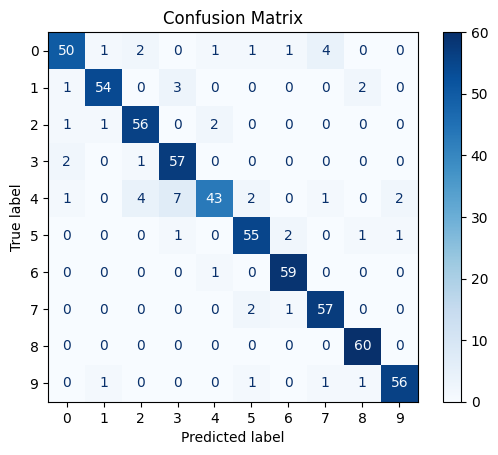

In [ ]:
#####################
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Predict the probabilities
predictions = model.predict(X_test, batch_size=batch_size)

# Convert probabilities to class predictions
predicted_classes = np.argmax(predictions, axis=1)

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_test, predicted_classes)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=np.arange(output_classes))
disp.plot(cmap=plt.cm.Blues)

plt.title("Confusion Matrix")
plt.show()

**adding noise to the test set**

In [ ]:
import numpy as np

def add_white_noise(data, snr_db):
    """
    Adds white noise to a dataset based on the desired Signal-to-Noise Ratio (SNR) in dB.

    Parameters:
    - data: Input spectrograms (numpy array of shape [num_samples, 128, 128, 1]).
    - snr_db: Desired SNR in decibels (float).

    Returns:
    - noisy_data: Spectrograms with added white noise.
    """
    noisy_data = []
    for sample in data:
        # Compute signal power
        signal_power = np.mean(sample**2)
        # Compute noise power based on SNR
        snr_linear = 10**(snr_db / 10)
        noise_power = signal_power / snr_linear
        # Generate white noise
        noise = np.sqrt(noise_power) * np.random.normal(size=sample.shape)
        # Add noise to the sample
        noisy_sample = sample + noise
        noisy_data.append(noisy_sample)

    return np.array(noisy_data)


**evaluating the model based on different levels of snrs**

In [ ]:
import matplotlib.pyplot as plt

# Define SNR levels (in dB) to test
snr_levels = [-10, -5, 0, 5, 10, 20]  # Example SNRs: very noisy to less noisy
accuracy_results = []

for snr in snr_levels:
    # Add white noise to the test set
    X_test_noisy = add_white_noise(X_test, snr)

    # Evaluate the model on the noisy test set
    test_loss, test_accuracy = model.evaluate(X_test_noisy, y_test, batch_size=batch_size, verbose=0)
    accuracy_results.append(test_accuracy)
    print(f"SNR: {snr} dB - Test Accuracy: {test_accuracy:.2f}")


SNR: -10 dB - Test Accuracy: 0.09
SNR: -5 dB - Test Accuracy: 0.10
SNR: 0 dB - Test Accuracy: 0.10
SNR: 5 dB - Test Accuracy: 0.13
SNR: 10 dB - Test Accuracy: 0.19
SNR: 20 dB - Test Accuracy: 0.44


**plotting evaluation of the model based on different levels of snrs**

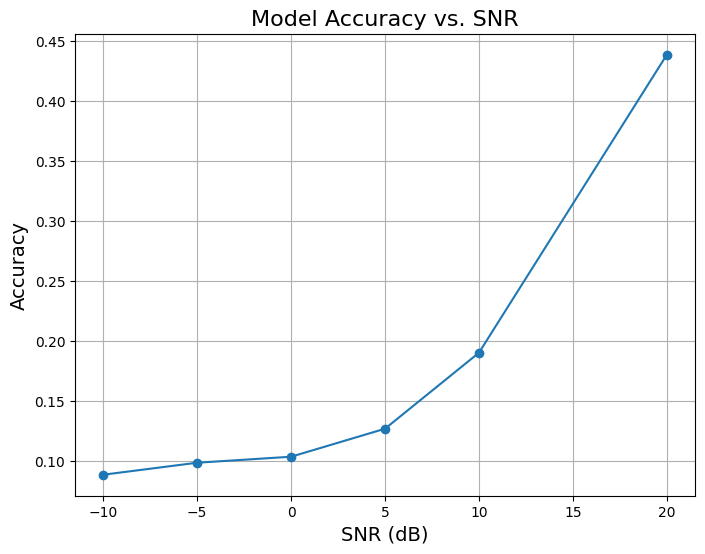

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(snr_levels, accuracy_results, marker='o')
plt.title("Model Accuracy vs. SNR", fontsize=16)
plt.xlabel("SNR (dB)", fontsize=14)
plt.ylabel("Accuracy", fontsize=14)
plt.grid(True)
plt.show()